## Model Price vs. Spare Capacity Metric v2
- add outage data, include uri dates
- seperate the price adder and rtm price

In [81]:
import pandas as pd
import numpy as np
from pathlib import Path
import matplotlib.pyplot as plt

GEN_PATH = '../../01_data/2_cleaned/generation/hourly_solar_wind_generation_2020_2025.parquet'
LOAD_PATH = '../../01_data/2_cleaned/load/total_load_20201231_20260526.csv'
CAPACITY_PATH = '../../01_data/2_cleaned/generation/ERCOT nonRE capacity 2020-2025.csv'
PRICE_PATH = '../../01_data/2_cleaned/rtm_price/rtm_price_aggregated_2021_2025.csv'
NG_PATH = '../../01_data/3_analysis/ng_price/ng_prices_monthly.csv'
TEMP_PATH = '../../01_data/2_cleaned/weather/Texas_hourly_temp_2021_2025.csv'

OUTAGE_PATH = '../../01_data/2_cleaned/outage/archive_1h_ahead_outage_20210101_2026_0924.parquet'
ADDER_PATH = '../../01_data/2_cleaned/price_adders/price_adders_hourly_20200101_20251204.csv'

OUT_DIR = Path('../../01_data/3_analysis/price incentive metrics')
MODEL_OUT_DIR = Path('../../01_data/4_model/')

In [82]:
df_outage = pd.read_parquet(OUTAGE_PATH)
df_outage['datetime'] = pd.to_datetime(df_outage['datetime'])
df_outage.head()

,datetime,totalResourceMW
0,2021-01-01 01:00:00,7754.0
1,2021-01-01 02:00:00,7681.0
2,2021-01-01 03:00:00,7681.0
3,2021-01-01 04:00:00,7681.0
4,2021-01-01 05:00:00,7681.0


In [83]:
df_adder = pd.read_csv(ADDER_PATH)
df_adder['datetime'] = pd.to_datetime(df_adder['datetime'])
df_adder.head()

,datetime,RTRSVPOR,RTRSVPOFF,RTRDP
0,2020-01-01 01:00:00,0.0,0.0,0.0
1,2020-01-01 02:00:00,0.0,0.0,0.0
2,2020-01-01 03:00:00,0.0,0.0,0.0
3,2020-01-01 04:00:00,0.0,0.0,0.0
4,2020-01-01 05:00:00,0.0,0.0,0.0


In [84]:
# import datasets
df_gen = pd.read_parquet(GEN_PATH)
df_gen['datetime'] = pd.to_datetime(df_gen['datetime'])
df_gen.head()

,datetime,renewable_gen
0,2020-01-01 01:00:00,12832.85
1,2020-01-01 02:00:00,13328.73
2,2020-01-01 03:00:00,13920.06
3,2020-01-01 04:00:00,14443.91
4,2020-01-01 05:00:00,14713.70


In [85]:
df_load = pd.read_csv(LOAD_PATH)
df_load['datetime'] = pd.to_datetime(df_load['datetime'])
df_load.head()

,datetime,total_load
0,2020-12-31 01:00:00,39174.39
1,2020-12-31 02:00:00,38284.84
2,2020-12-31 03:00:00,37776.69
3,2020-12-31 04:00:00,37781.84
4,2020-12-31 05:00:00,38455.69


In [86]:
df_capacity = pd.read_csv(CAPACITY_PATH)
df_total_cap = df_capacity.filter(['year', 'total_mw'])
df_total_cap = df_total_cap.rename(columns={'total_mw': 'non_re_capacity'})
df_total_cap['non_re_capacity'] = df_total_cap['non_re_capacity'].astype(int)
df_total_cap

,year,non_re_capacity
0,2020,65518
1,2021,66390
2,2022,67023
3,2023,68028
4,2024,68766
5,2025,68624


In [87]:
df_price = pd.read_csv(PRICE_PATH)
df_price = df_price.filter(['date_time', 'avg_rtm_price'])
df_price = df_price.rename(columns={'date_time': 'datetime', 'avg_rtm_price' : 'rtm_price'})
df_price['datetime'] = pd.to_datetime(df_price['datetime'])
df_price.describe()

,datetime,rtm_price
count,43819,43819.000000
mean,2023-07-03 00:48:33.010338,64.376905
min,2021-01-01 01:00:00,-31.813667
25%,2022-04-02 13:30:00,17.660250
50%,2023-07-03 01:00:00,25.110000
75%,2024-10-01 12:30:00,40.307000
max,2026-01-01 00:00:00,9030.790833
std,NaN,451.163681


In [88]:
df_ng = pd.read_csv(NG_PATH)
df_ng['date'] = pd.to_datetime(df_ng['date'])
df_ng['month'] = df_ng['date'].dt.month
df_ng['year'] = df_ng['date'].dt.year

df_ng.head()

,date,henry_hub,citygate,elec_pwr,outlier_citygate,outlier_elec_pwr,month,year
0,2002-01-01,2.317619,3.304432,2.552987,False,False,1,2002
1,2002-02-01,2.323684,3.111753,2.273603,False,False,2,2002
2,2002-03-01,3.028500,3.121387,2.851638,False,False,3,2002
3,2002-04-01,3.426818,4.065511,3.439306,False,False,4,2002
4,2002-05-01,3.498182,4.007707,3.391137,False,False,5,2002


In [89]:
df_temp = pd.read_csv(TEMP_PATH)
df_temp

,datetime,tx_temp
0,2021-01-01 01:00:00,35.301445
1,2021-01-01 02:00:00,34.923515
2,2021-01-01 03:00:00,34.651550
3,2021-01-01 04:00:00,33.962486
4,2021-01-01 05:00:00,32.179900
...,...,...
43814,2025-12-31 20:00:00,56.684467
43815,2025-12-31 21:00:00,51.554237
43816,2025-12-31 22:00:00,50.368977
43817,2025-12-31 23:00:00,49.432446


### Data Cleaning
1. power price without adders

In [90]:
df_agg_price = pd.merge(df_price, df_adder, on='datetime')
df_agg_price

,datetime,rtm_price,RTRSVPOR,RTRSVPOFF,RTRDP
0,2021-01-01 01:00:00,18.173500,0.0,0.0,0.00
1,2021-01-01 02:00:00,20.960833,0.0,0.0,0.00
2,2021-01-01 03:00:00,20.779667,0.0,0.0,0.00
3,2021-01-01 04:00:00,16.416667,0.0,0.0,0.00
4,2021-01-01 05:00:00,18.075333,0.0,0.0,0.00
...,...,...,...,...,...
43141,2025-12-03 19:00:00,37.520333,0.0,0.0,0.01
43142,2025-12-03 20:00:00,40.374667,0.0,0.0,0.00
43143,2025-12-03 21:00:00,38.039500,0.0,0.0,0.00
43144,2025-12-03 22:00:00,34.266667,0.0,0.0,0.00


In [91]:
df_agg_price['price_wo_adders'] = df_agg_price['rtm_price'] - df_agg_price['RTRSVPOR'] - df_agg_price['RTRDP']
df_agg_price

,datetime,rtm_price,RTRSVPOR,RTRSVPOFF,RTRDP,price_wo_adders
0,2021-01-01 01:00:00,18.173500,0.0,0.0,0.00,18.173500
1,2021-01-01 02:00:00,20.960833,0.0,0.0,0.00,20.960833
2,2021-01-01 03:00:00,20.779667,0.0,0.0,0.00,20.779667
3,2021-01-01 04:00:00,16.416667,0.0,0.0,0.00,16.416667
4,2021-01-01 05:00:00,18.075333,0.0,0.0,0.00,18.075333
...,...,...,...,...,...,...
43141,2025-12-03 19:00:00,37.520333,0.0,0.0,0.01,37.510333
43142,2025-12-03 20:00:00,40.374667,0.0,0.0,0.00,40.374667
43143,2025-12-03 21:00:00,38.039500,0.0,0.0,0.00,38.039500
43144,2025-12-03 22:00:00,34.266667,0.0,0.0,0.00,34.266667


In [92]:
# export 
df_agg_price.to_csv(OUT_DIR / 'rtm_adder_aggregated_20210101_20251203.csv', index=False)

### Metric 2: spare capacity calculation
1. include uri points this time, because the outage data is included
2. metric2: evaluates spare capacity accounting for outage; 
    - (hourly load - hourly renewable_gen) / (non_re_capacity - hourly outage)

In [93]:
import duckdb

# price without adders
con = duckdb.connect()
df_metric = con.execute("""
   WITH Merged AS (
      SELECT
         g.datetime
         ,price_wo_adders
         ,renewable_gen
         ,total_load
         ,non_re_capacity
         ,totalResourceMW AS outage
      FROM df_gen g
      INNER JOIN df_load l ON g.datetime = l.datetime
      LEFT JOIN df_total_cap c ON YEAR(g.datetime) = c.year
      JOIN df_agg_price p ON g.datetime = p.datetime
      JOIN df_outage o ON o.datetime = g.datetime               
      )
   
   SELECT
         datetime
         ,YEAR(datetime) AS year
         ,price_wo_adders
         ,(total_load - renewable_gen)/(non_re_capacity - outage) AS metric2
   FROM Merged
   ORDER BY datetime;
""").fetchdf()

df_metric

,datetime,year,price_wo_adders,metric2
0,2021-01-01 01:00:00,2021,18.173500,0.507010
1,2021-01-01 02:00:00,2021,20.960833,0.494391
2,2021-01-01 03:00:00,2021,20.779667,0.491019
3,2021-01-01 04:00:00,2021,16.416667,0.508057
4,2021-01-01 05:00:00,2021,18.075333,0.531662
...,...,...,...,...
43144,2025-12-03 19:00:00,2025,37.510333,0.840561
43145,2025-12-03 20:00:00,2025,40.374667,0.784120
43146,2025-12-03 21:00:00,2025,38.039500,0.739089
43147,2025-12-03 22:00:00,2025,34.266667,0.695477


### Local Regression by year slices

In [94]:
import statsmodels.api as sm
def lowess_fit(x, y, color, label):
    
    # 2. Apply LOWESS local regression
    # frac: the fraction of data used when estimating each y-value (controls smoothing)
    lowess_result = sm.nonparametric.lowess(y, x, frac=0.1)

    # Extract sorted x and predicted y values
    x_smooth = lowess_result[:, 0]
    y_smooth = lowess_result[:, 1]

    # plot
    plt.scatter(x, y, color='lightgray', s=15)
    plt.plot(x_smooth, y_smooth, color=color, linewidth=2, label=f"{label} LOWESS Fit")
    plt.legend()

/var/folders/0q/ndh_pk0s37n95y6svtjfy7hw0000gp/T/ipykernel_25074/2013854203.py:20: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend(fontsize=16, frameon=False)


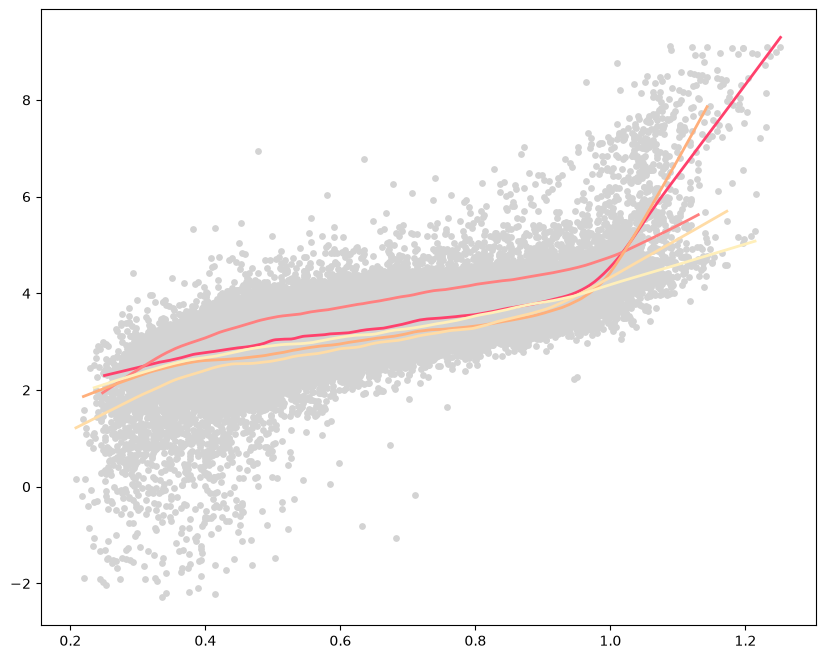

In [95]:
fig, ax = plt.subplots(figsize=(10, 8))
years = [2021, 2022, 2023, 2024, 2025]
colors = ['#FF416C', '#FF8080', '#FFAF7B', '#FFDCA6', '#FFEFBA']

df = df_metric.copy()
df = df[df['price_wo_adders'] >= 0.1]

for year, color in zip(years, colors):
    df_year = df[df['year'] == year]
    x = df_year['metric2']
    y = np.log(df_year['price_wo_adders'])

    lowess_fit = sm.nonparametric.lowess(y, x, frac=0.1)
    x_smooth = lowess_fit[:, 0]
    y_smooth = lowess_fit[:, 1]

    ax.scatter(x, y, color='lightgray', s=15)
    ax.plot(x_smooth, y_smooth, color=color, linewidth=2)

ax.legend(fontsize=16, frameon=False)

/Users/zyliazhang/Git/ERCOT-Research/.venv/lib/python3.14/site-packages/pandas/core/arraylike.py:402: RuntimeWarning: invalid value encountered in log
  result = getattr(ufunc, method)(*inputs, **kwargs)
/Users/zyliazhang/Git/ERCOT-Research/.venv/lib/python3.14/site-packages/pandas/core/arraylike.py:402: RuntimeWarning: divide by zero encountered in log
  result = getattr(ufunc, method)(*inputs, **kwargs)


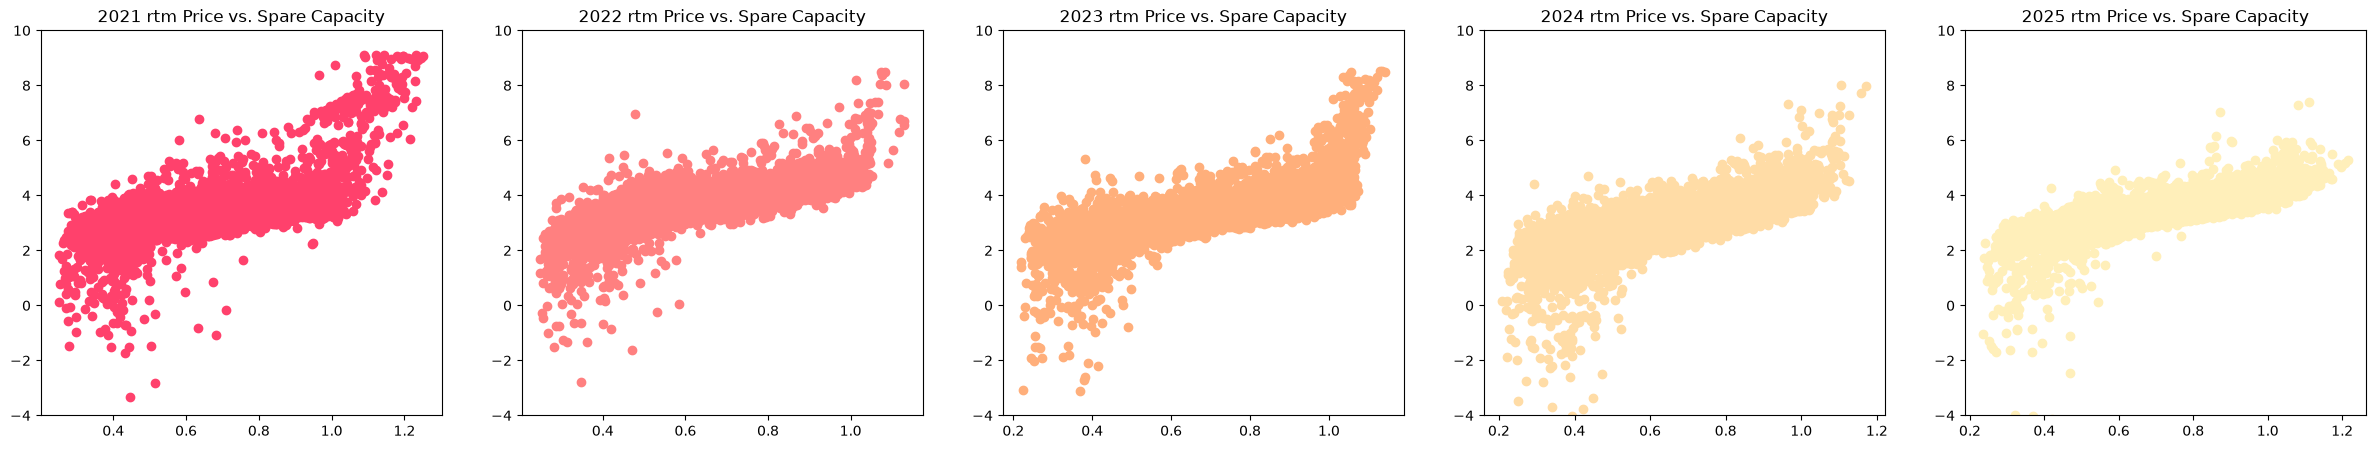

In [96]:
fig, axs = plt.subplots(1, 5, figsize=(30, 5))
for i, year in enumerate(years):
    df_year = df_metric[df_metric['year'] == year]
    axs[i].scatter(df_year['metric2'], np.log(df_year['price_wo_adders']), color=colors[i])
    axs[i].set_ylim(-4, 10)
    axs[i].set_title(f'{year} rtm Price vs. Spare Capacity')

### Slice by monthly timeseries

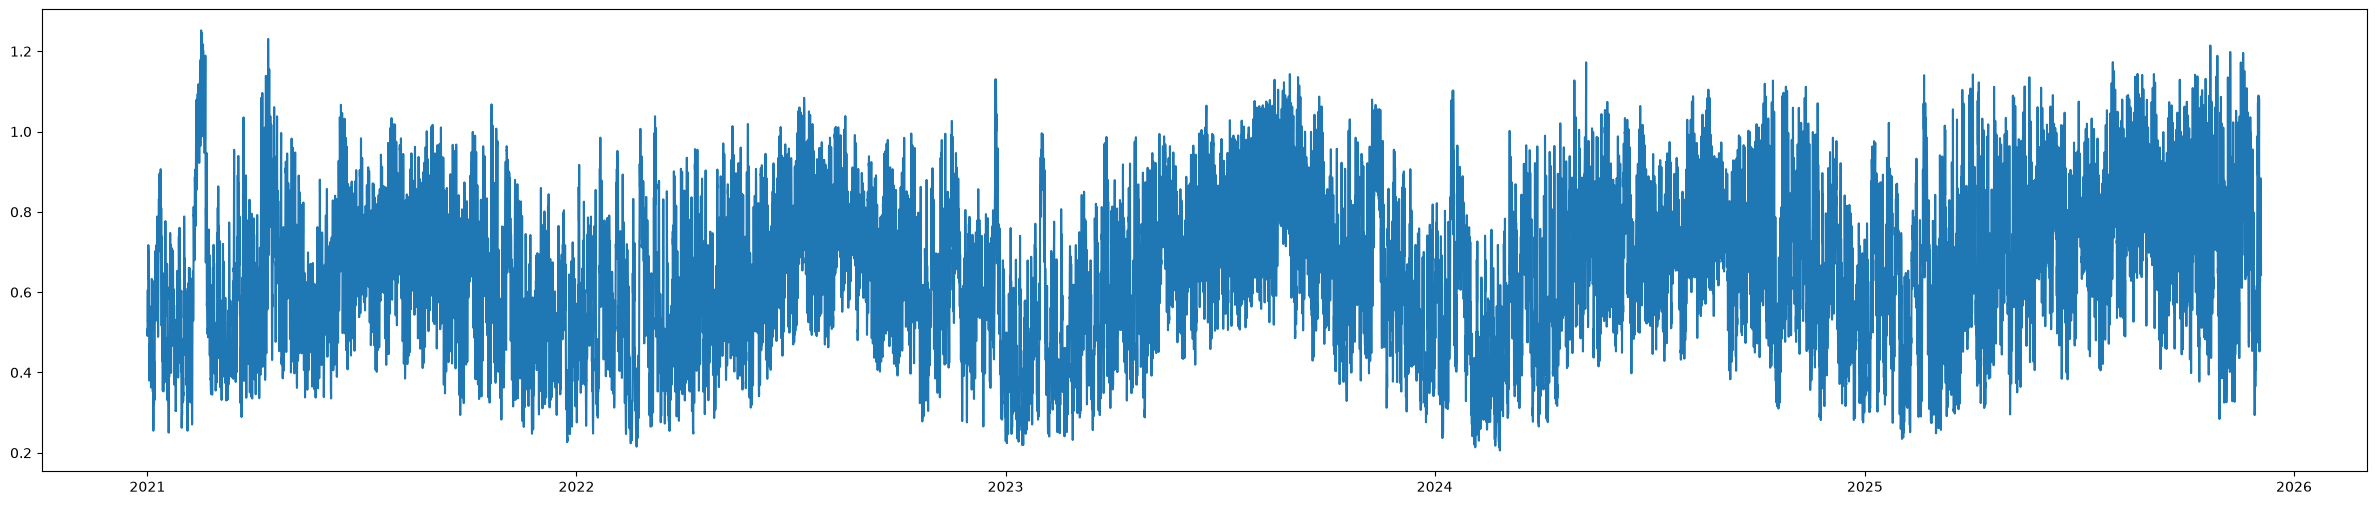

In [97]:
fig, ax = plt.subplots(figsize=(30, 6))
ax.plot(df_metric['datetime'] , df_metric['metric2'])

In [98]:
df_metric.groupby('year').mean()['metric2']

year
2021    0.626116
2022    0.624480
2023    0.644911
2024    0.640606
2025    0.684614
Name: metric2, dtype: float64

Text(0, 0.5, 'Spare Capacity')

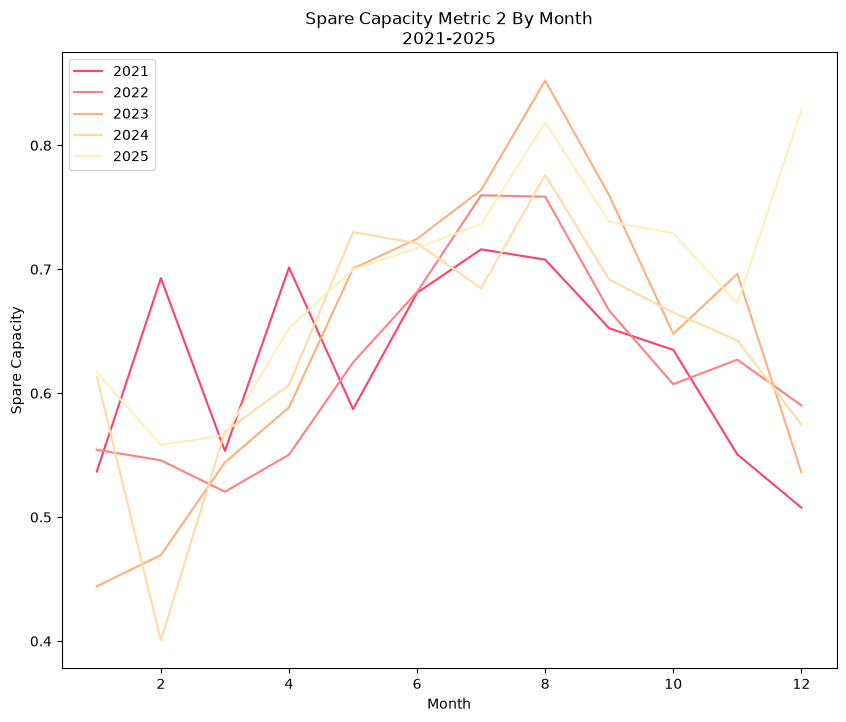

In [99]:
plt.figure(figsize=(10, 8))
df_month = df_metric.copy()
df_month['month'] = df_month['datetime'].dt.month

for year, color in zip(df_month['year'].unique(), colors):
    df = df_month[df_month['year']==year]
    df = df.groupby(df['datetime'].dt.month).mean()
    plt.plot(df['month'] , df['metric2'], color=color, label=year)
plt.legend()
plt.title('Spare Capacity Metric 2 By Month\n2021-2025')
plt.xlabel('Month')
plt.ylabel('Spare Capacity')

### Natural Gas color coding

In [100]:
df_metric_with_ng = con.execute("""
      SELECT 
         m.datetime
         ,price_wo_adders
         ,metric2 AS capacity
         ,citygate AS ng_price
      FROM df_metric m
         LEFT JOIN df_ng n ON n.month = MONTH(m.datetime)
                           AND n.year = m.year                         
      ORDER BY n.year, n.month;
""").fetchdf()

df_metric_with_ng

,datetime,price_wo_adders,capacity,ng_price
0,2021-01-01 01:00:00,18.173500,0.507010,2.909441
1,2021-01-01 02:00:00,20.960833,0.494391,2.909441
2,2021-01-01 03:00:00,20.779667,0.491019,2.909441
3,2021-01-01 04:00:00,16.416667,0.508057,2.909441
4,2021-01-01 05:00:00,18.075333,0.531662,2.909441
...,...,...,...,...
43144,2025-12-03 19:00:00,37.510333,0.840561,4.065511
43145,2025-12-03 20:00:00,40.374667,0.784120,4.065511
43146,2025-12-03 21:00:00,38.039500,0.739089,4.065511
43147,2025-12-03 22:00:00,34.266667,0.695477,4.065511


In [101]:
np.log(10)

np.float64(2.302585092994046)

/Users/zyliazhang/Git/ERCOT-Research/.venv/lib/python3.14/site-packages/pandas/core/arraylike.py:402: RuntimeWarning: divide by zero encountered in log
  result = getattr(ufunc, method)(*inputs, **kwargs)
/Users/zyliazhang/Git/ERCOT-Research/.venv/lib/python3.14/site-packages/pandas/core/arraylike.py:402: RuntimeWarning: invalid value encountered in log
  result = getattr(ufunc, method)(*inputs, **kwargs)


Text(0.5, 1.0, 'Without Adder Price (Log) vs. Spare Capacity colored by NG Price (Log)\n2021-2025')

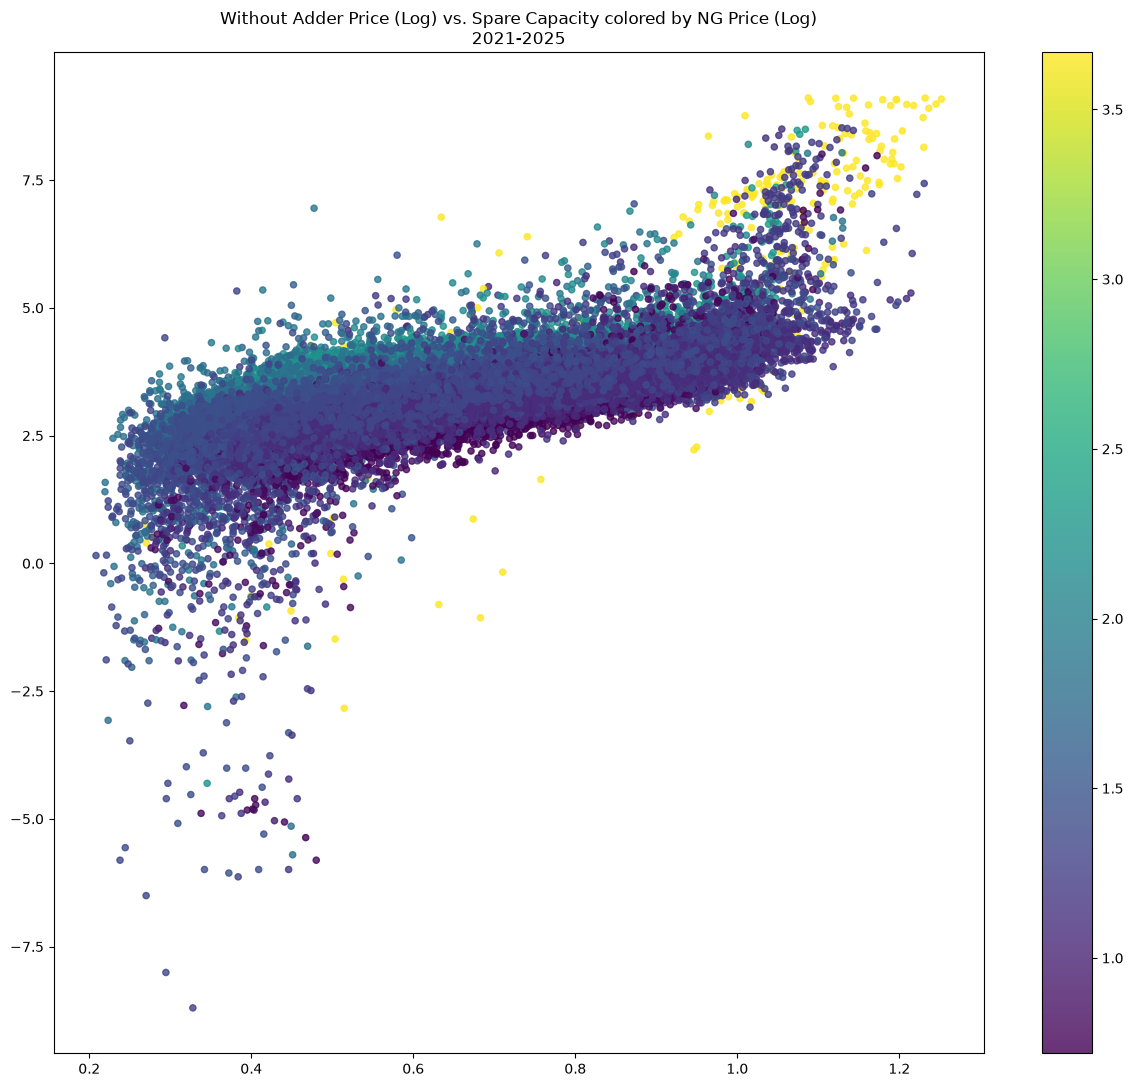

In [102]:
df = df_metric_with_ng.copy()

df = df[df['ng_price'] >= 0.1]
plt.figure(figsize=(15, 13))
plt.scatter(df['capacity'], np.log(df['price_wo_adders']), c=np.log(df['ng_price']), alpha=0.8, s=20)
plt.colorbar()
plt.title('Without Adder Price (Log) vs. Spare Capacity colored by NG Price (Log)\n2021-2025')

/var/folders/0q/ndh_pk0s37n95y6svtjfy7hw0000gp/T/ipykernel_25074/3023383114.py:25: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


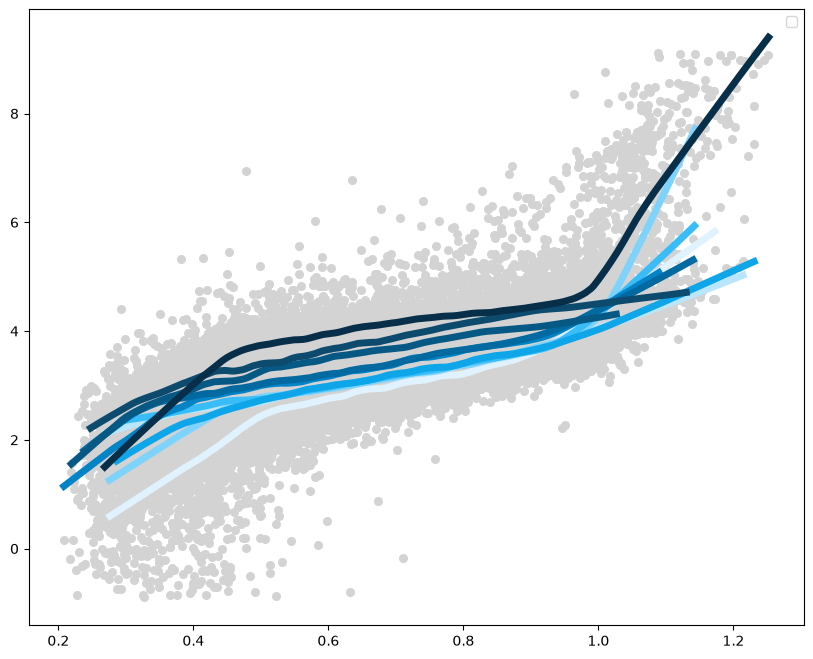

In [141]:
df = df_metric_with_ng.copy()
df = df.dropna()
df = df[df['price_wo_adders'] >= 0.4]
df['ng_bins'] = pd.qcut(df['ng_price'], 10)
df_bins = df.sort_values('ng_bins')

fig, ax = plt.subplots(figsize=(10, 8))

colors10 = ['#E0F2FE', '#BAE6FD', '#7DD3FC', '#38BDF8', '#0EA5E9', '#0284C7', '#0369A1', '#075985', '#0C4A6E', '#082F49']

import statsmodels.api as sm
def lowess_fit(x, y, color, label):
    
    # 2. Apply LOWESS local regression
    # frac: the fraction of data used when estimating each y-value (controls smoothing)
    lowess_result = sm.nonparametric.lowess(y, x, frac=0.1)

    # Extract sorted x and predicted y values
    x_smooth = lowess_result[:, 0]
    y_smooth = lowess_result[:, 1]

    # plot
    plt.scatter(x, y, color='lightgray', s=30)
    plt.plot(x_smooth, y_smooth, color=color, linewidth=5, label=f"{label} LOWESS Fit")
    plt.legend()

for bin, color in zip(df_bins['ng_bins'].unique(), colors10):
    df_bin = df_bins[df_bins['ng_bins'] == bin]
    lowess_fit(df_bin['capacity'], np.log(df_bin['price_wo_adders']), color, '_nolegend_')

#plt.title('Power Price vs. Spare Capacity by NG Price Quantiles')
#plt.ylabel('Power Price (Log)')
#plt.xlabel('Capacity Utilization Ratio')

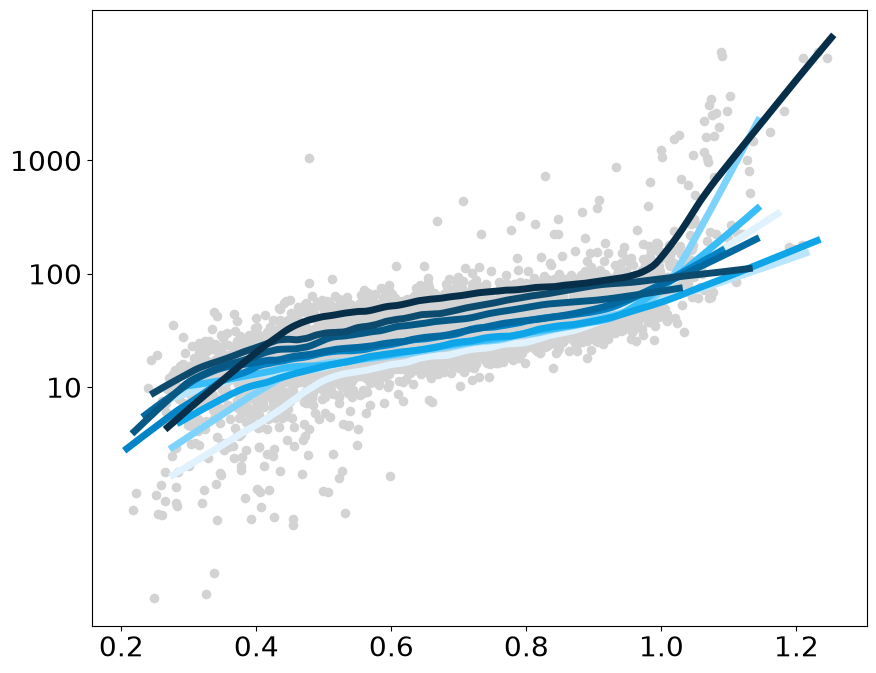

In [148]:
df = df_metric_with_ng.copy()
df = df.dropna()
df = df[df['price_wo_adders'] >= 0.1]
df['ng_bins'] = pd.qcut(df['ng_price'], 10)
df_bins = df.sort_values('ng_bins')

fig, ax = plt.subplots(figsize=(10, 8))

colors10 = ['#E0F2FE', '#BAE6FD', '#7DD3FC', '#38BDF8', '#0EA5E9', '#0284C7', '#0369A1', '#075985', '#0C4A6E', '#082F49']

def lowess_fit(x, y, color, label):
    lowess_result = sm.nonparametric.lowess(y, x, frac=0.1)
    x_smooth = lowess_result[:, 0]
    y_smooth = lowess_result[:, 1]
    
    # Sample 10% of points for scatter
    sample_indices = np.random.choice(len(x), size=max(1, len(x)//10), replace=False)
    ax.scatter(x.iloc[sample_indices], y.iloc[sample_indices], color='lightgray', s=35)
    ax.plot(x_smooth, y_smooth, color=color, linewidth=5, label=f"{label} LOWESS Fit")

for bin, color in zip(df_bins['ng_bins'].unique(), colors10):
    df_bin = df_bins[df_bins['ng_bins'] == bin]
    lowess_fit(df_bin['capacity'], np.log(df_bin['price_wo_adders']), color, '_nolegend_')

# Format y-axis ticks to show [10, 100, 1000]
ax.set_yticks([np.log(10), np.log(100), np.log(1000)])
ax.set_yticklabels(['10', '100', '1000'], fontsize=20)
ax.tick_params(axis='x', labelsize=20)

### Temp Color Coding

In [104]:
df_metric_with_temp = con.execute("""
      SELECT 
         m.datetime
         ,ABS(tx_temp - 65) AS degree_days
         ,price_wo_adders
         ,metric2 AS capacity
      FROM df_metric m
         LEFT JOIN df_temp t ON t.datetime = m.datetime                        
      ORDER BY m.datetime;
""").fetchdf()
df_metric_with_temp

,datetime,degree_days,price_wo_adders,capacity
0,2021-01-01 01:00:00,29.698555,18.173500,0.507010
1,2021-01-01 02:00:00,30.076485,20.960833,0.494391
2,2021-01-01 03:00:00,30.348450,20.779667,0.491019
3,2021-01-01 04:00:00,31.037514,16.416667,0.508057
4,2021-01-01 05:00:00,32.820100,18.075333,0.531662
...,...,...,...,...
43144,2025-12-03 19:00:00,9.542927,37.510333,0.840561
43145,2025-12-03 20:00:00,10.943300,40.374667,0.784120
43146,2025-12-03 21:00:00,12.875572,38.039500,0.739089
43147,2025-12-03 22:00:00,13.614403,34.266667,0.695477


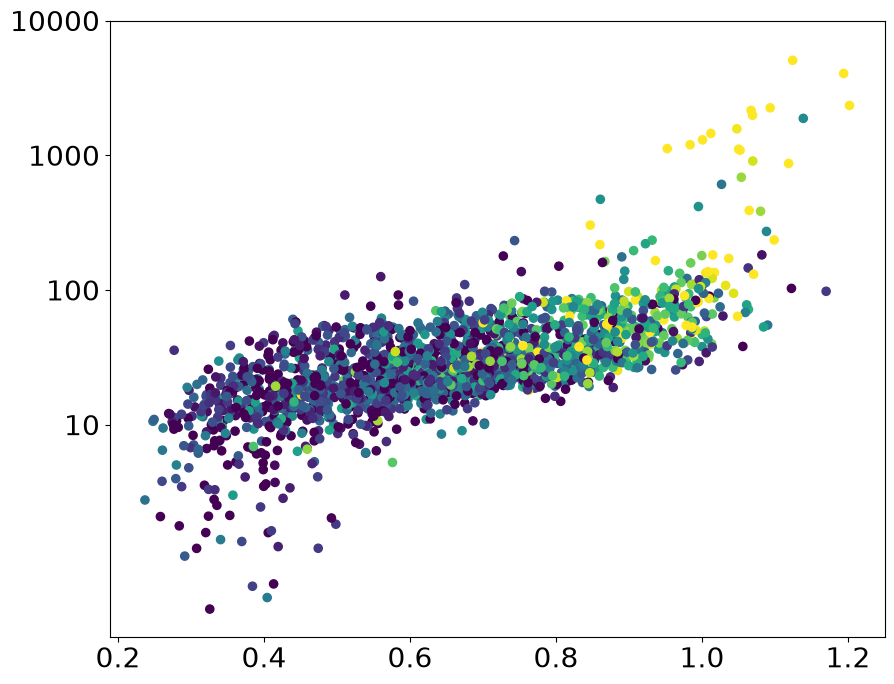

In [ ]:
# poster version: Log-Scaled Power Price vs. Capacity Utilization by Temperature
import matplotlib.ticker as ticker

df = df_metric_with_temp.copy()
df = df.sample(frac=0.05)
df = df[df['price_wo_adders'] >= 0.4]

fig, ax = plt.subplots(figsize=(10, 8))

x = df["capacity"]
y = df["price_wo_adders"]

im = ax.scatter(x, y, s=35, alpha=1, c=df['degree_days'], cmap="viridis", vmin=5, vmax=35)

# 1. Set the y-axis to log scale with base e
ax.set_yscale('log', base=np.e)

# Set yticks at powers of 10
ax.set_yticks([10, 100, 1000, 10000])
ax.yaxis.set_major_formatter(ticker.ScalarFormatter())
ax.tick_params(axis="y", labelsize=20)
ax.tick_params(axis="x", labelsize=20)

plt.show()

/Users/zyliazhang/Git/ERCOT-Research/.venv/lib/python3.14/site-packages/pandas/core/arraylike.py:402: RuntimeWarning: divide by zero encountered in log
  result = getattr(ufunc, method)(*inputs, **kwargs)
/Users/zyliazhang/Git/ERCOT-Research/.venv/lib/python3.14/site-packages/pandas/core/arraylike.py:402: RuntimeWarning: invalid value encountered in log
  result = getattr(ufunc, method)(*inputs, **kwargs)


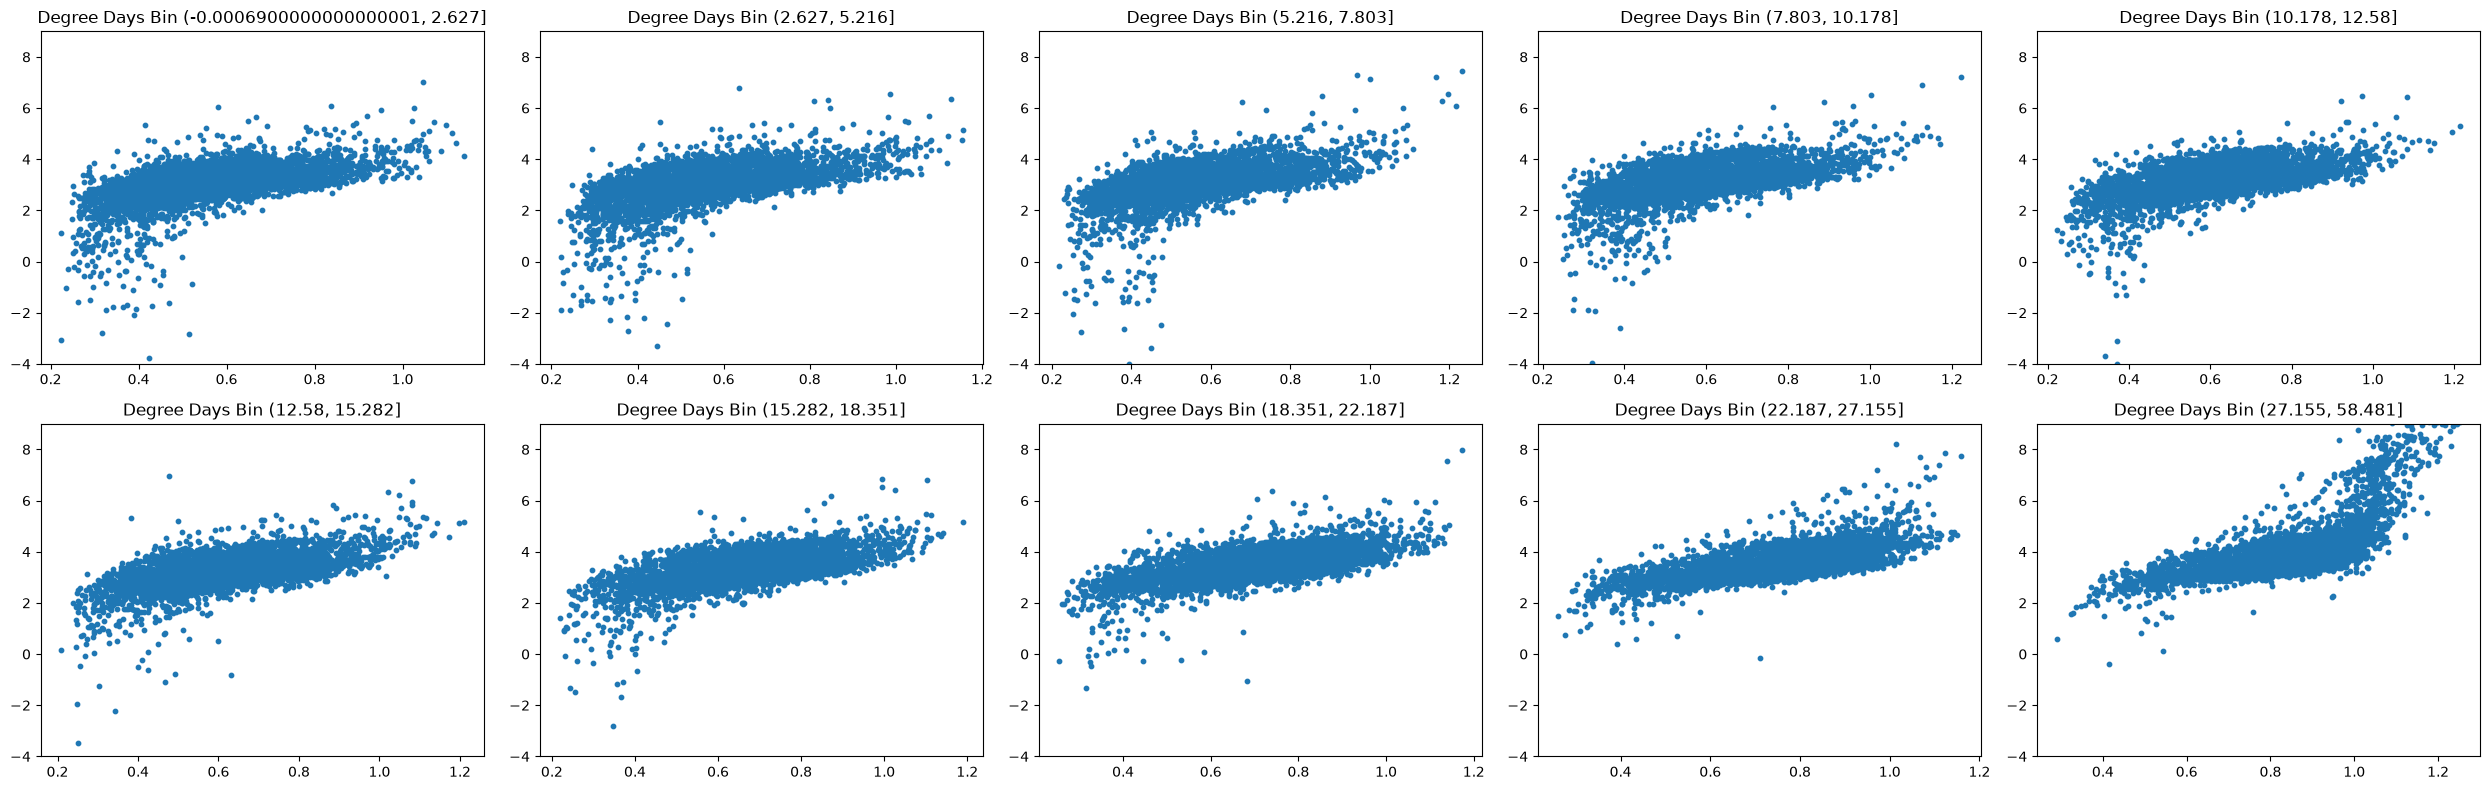

In [ ]:
df = df_metric_with_temp.copy()
df = df.dropna()
df['dd_bins'] = pd.qcut(df['degree_days'], 10, duplicates='drop')
df_bins = df.sort_values('degree_days')

fig, axes = plt.subplots(2, 5, figsize=(25, 8))

for cat, ax in zip(df_bins['dd_bins'].unique(), axes.flat):
    df_bin = df_bins[df_bins['dd_bins'] == cat]
    ax.scatter(df_bin['capacity'], np.log(df_bin['price_wo_adders']), s=10)
    ax.set_title(f'Degree Days Bin {cat}')
    ax.set_ylim(-4, 9)
plt.tight_layout()
plt.show()